In [1]:
import sys
sys.path.insert(0, "..")  # repository root, so `import km5c` works
from km5c.paths import FIG_DIR
from km5c.plotting import latdepthplot, shade_below_bathymetry, temperatureadjustedplot
from km5c.models import load_hadcm3, load_icesm12, load_icesm13

hadcm3 = load_hadcm3()
hadcm3_Plio_d18O = hadcm3.Plio_d18O
hadcm3_Plio_depth = hadcm3.Plio_depth
hadcm3_Plio_lat = hadcm3.Plio_lat
hadcm3_Plio_lon = hadcm3.Plio_lon
hadcm3_Plio_temp = hadcm3.Plio_temp
hadcm3_preind_d18O = hadcm3.preind_d18O
hadcm3_preind_depth = hadcm3.preind_depth
hadcm3_preind_lat = hadcm3.preind_lat
hadcm3_preind_lon = hadcm3.preind_lon
hadcm3_preind_temp = hadcm3.preind_temp

icesm12 = load_icesm12()
Plio_d18O = icesm12.Plio_d18O
Plio_depth = icesm12.Plio_depth
Plio_lat = icesm12.Plio_lat
Plio_lon = icesm12.Plio_lon
Plio_temp = icesm12.Plio_temp
preind_d18O = icesm12.preind_d18O
preind_depth = icesm12.preind_depth
preind_lat = icesm12.preind_lat
preind_lon = icesm12.preind_lon
preind_temp = icesm12.preind_temp
preind_temp_lat = icesm12.preind_temp_lat
preind_temp_lon = icesm12.preind_temp_lon

icesm13 = load_icesm13()
icesm13_Plio_d18O = icesm13.Plio_d18O
icesm13_Plio_depth = icesm13.Plio_depth
icesm13_Plio_lat = icesm13.Plio_lat
icesm13_Plio_lon = icesm13.Plio_lon
icesm13_Plio_temp = icesm13.Plio_temp
icesm13_preind_d18O = icesm13.preind_d18O
icesm13_preind_depth = icesm13.preind_depth
icesm13_preind_lat = icesm13.preind_lat
icesm13_preind_lon = icesm13.preind_lon
icesm13_preind_temp = icesm13.preind_temp

(1, 60, 180, 360)
(60, 180, 360)


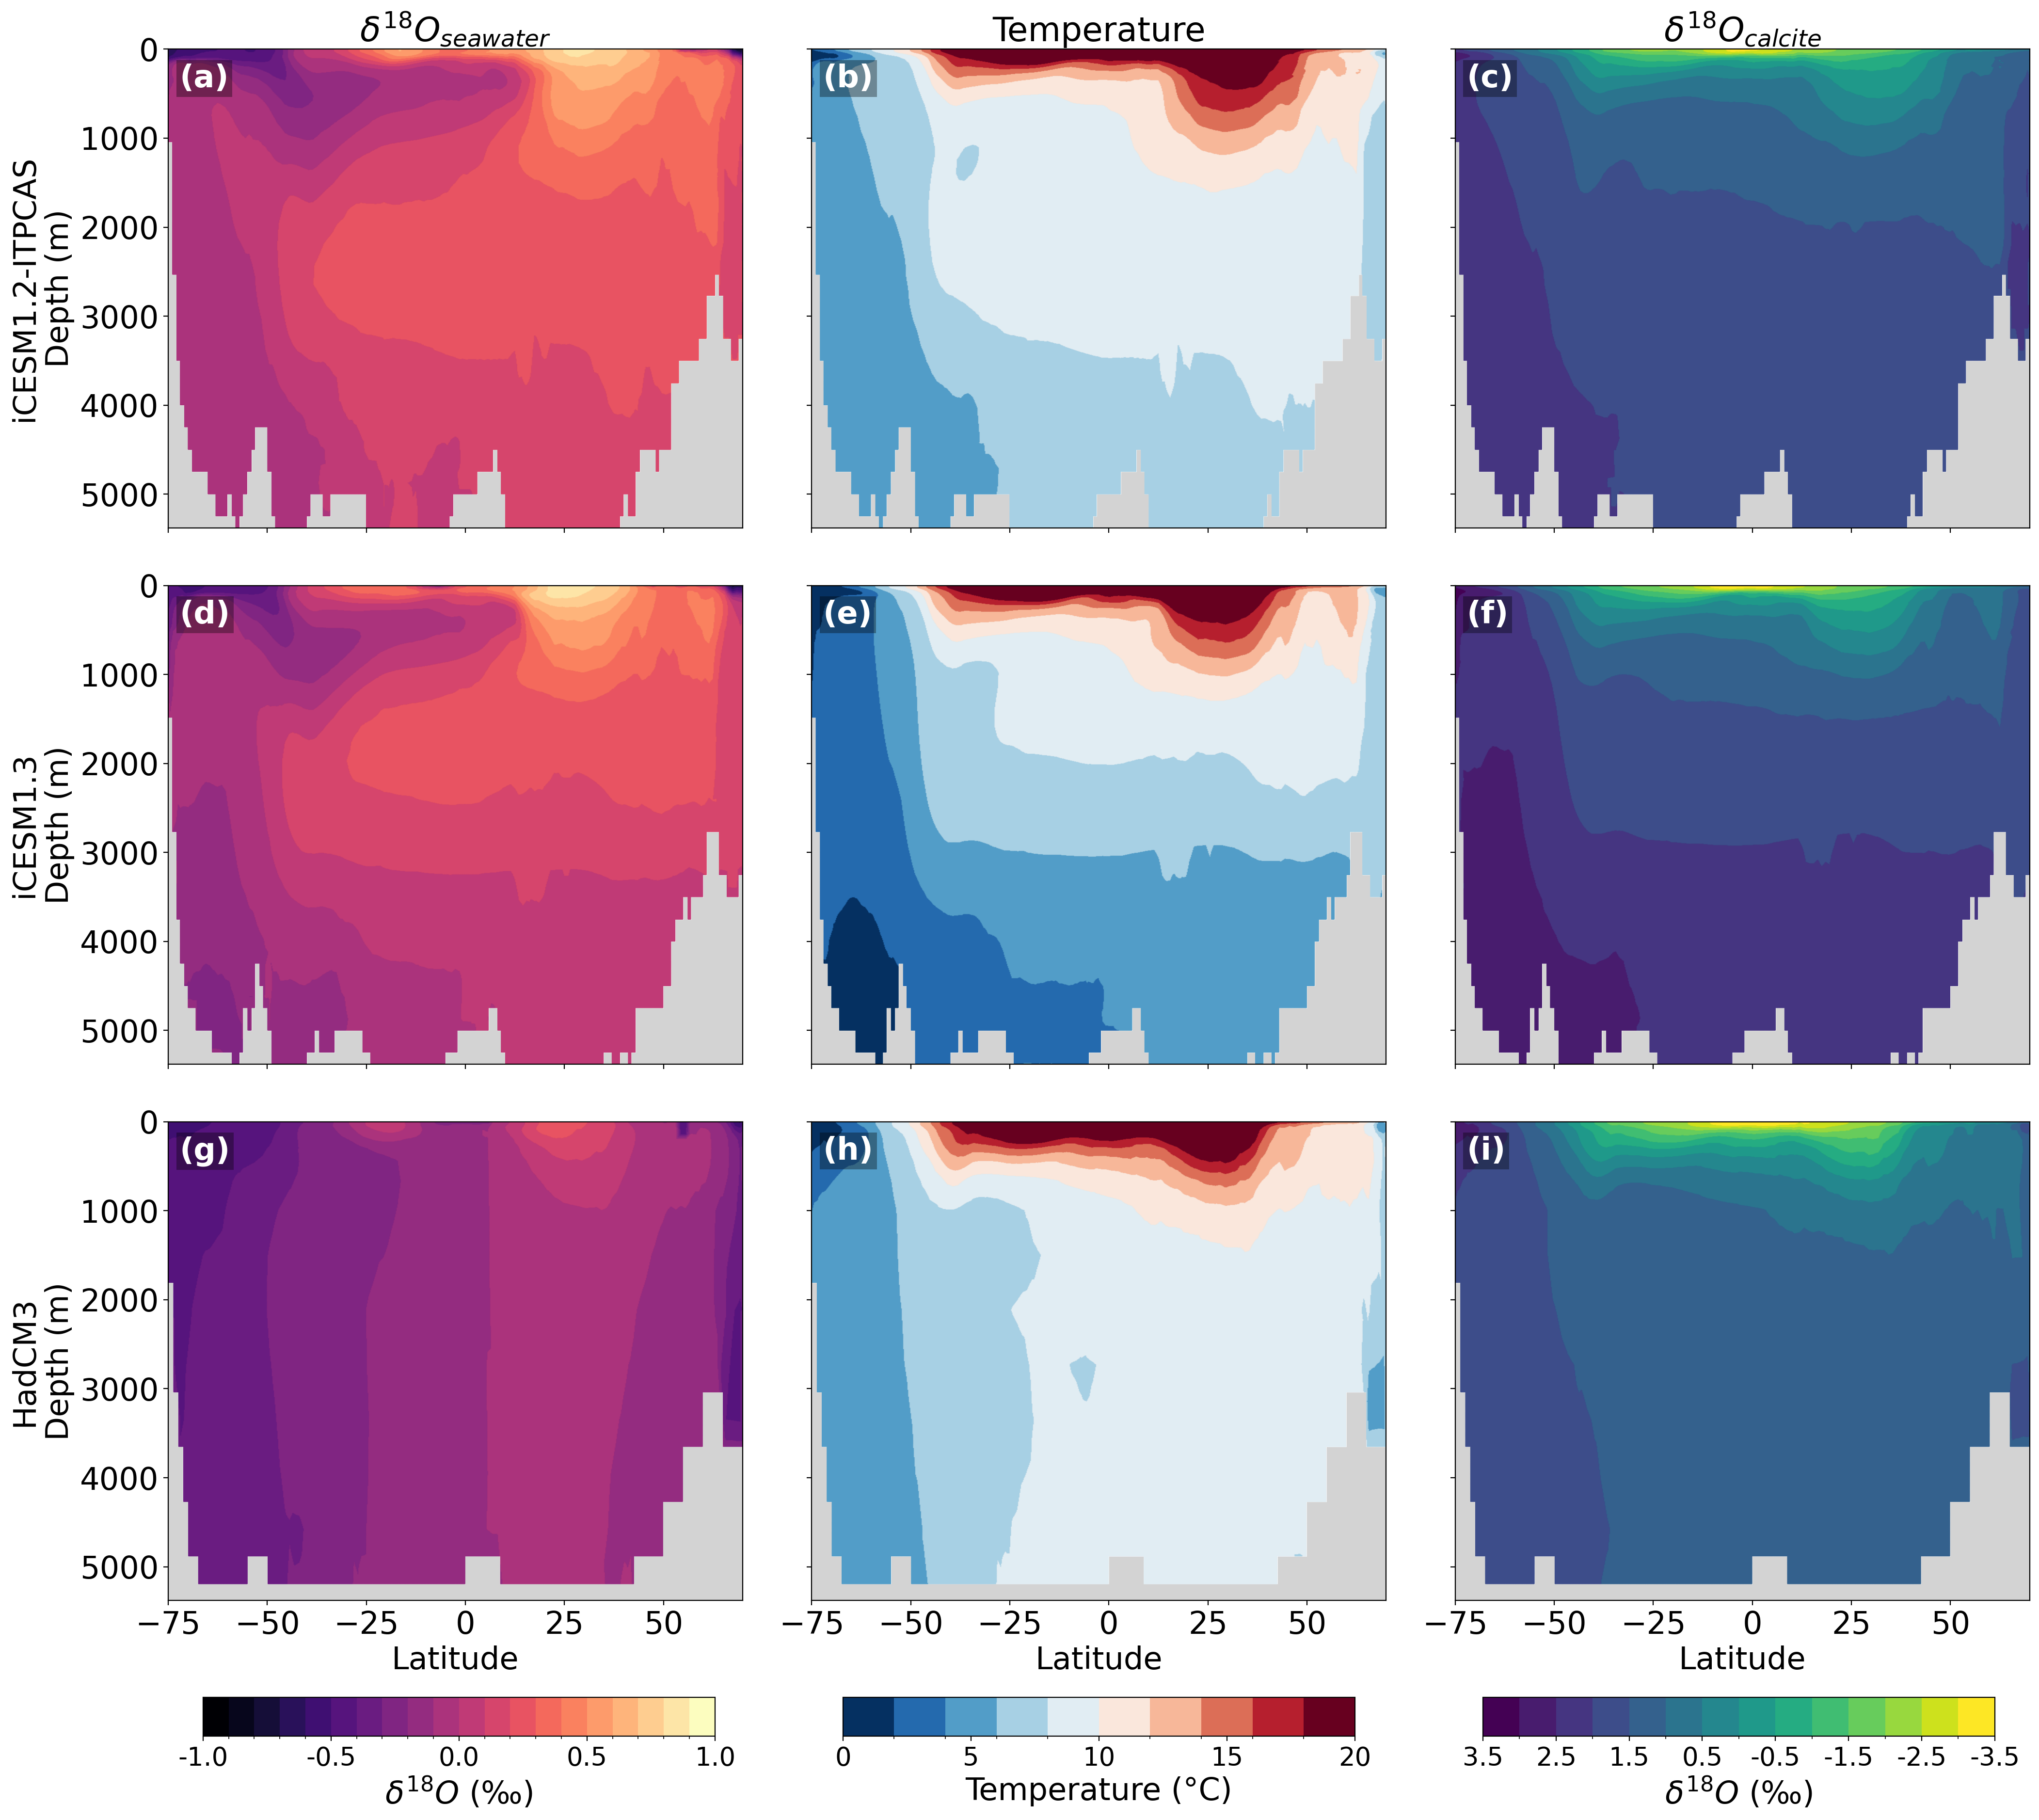

In [2]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.gridspec import GridSpec

# Define font sizes
TITLE_SIZE = 25
LABEL_SIZE = 23
TICK_SIZE = 23
CBAR_LABEL_SIZE = 23
CBAR_TICK_SIZE = 19

# Create figure
fig = plt.figure(figsize=(24, 20), dpi=200)

# Create a single GridSpec for the 3x3 plot grid
gs = GridSpec(3, 3, figure=fig,
              top=0.94,
              bottom=0.14,
              left=0.10,
              right=0.90,
              hspace=0.12,
              wspace=0.12)

# Set global font sizes
plt.rcParams['font.size'] = LABEL_SIZE
plt.rcParams['axes.titlesize'] = TITLE_SIZE
plt.rcParams['axes.labelsize'] = LABEL_SIZE
plt.rcParams['xtick.labelsize'] = TICK_SIZE
plt.rcParams['ytick.labelsize'] = TICK_SIZE

# Define column titles (only for top row)
column_titles = [r'$\delta^{18}O_{seawater}$', 'Temperature', r'$\delta^{18}O_{calcite}$']

# Define row titles (model names, on the left)
row_titles = ['iCESM1.2-ITPCAS', 'iCESM1.3', 'HadCM3']

# Define colormaps and normalization for each column
col1_color_bins = np.arange(-1, 1.01, 0.1)
col1_num_colors = len(col1_color_bins) - 1
col1_colors = plt.cm.magma(np.linspace(0, 1, col1_num_colors))
col1_cmap = mcolors.ListedColormap(col1_colors)
col1_norm = mcolors.BoundaryNorm(boundaries=col1_color_bins, ncolors=col1_num_colors)

col2_color_bins = np.arange(0, 21, 2)
col2_num_colors = len(col2_color_bins) - 1
col2_colors = plt.cm.RdBu_r(np.linspace(0, 1, col2_num_colors))
col2_cmap = mcolors.ListedColormap(col2_colors)
col2_norm = mcolors.BoundaryNorm(boundaries=col2_color_bins, ncolors=col2_num_colors)

col3_color_bins = np.arange(-3.5, 3.6, 0.5)
col3_num_colors = len(col3_color_bins) - 1
col3_colors = plt.cm.viridis_r(np.linspace(0, 1, col3_num_colors))
col3_cmap = mcolors.ListedColormap(col3_colors)
col3_norm = mcolors.BoundaryNorm(boundaries=col3_color_bins, ncolors=col3_num_colors)


# Create a list to store all plots for reference
plots = []

# ROW 1
# First plot (top-left)
ax1 = fig.add_subplot(gs[0, 0])
testplot1_row1, lat1_row1, depth1_row1 = latdepthplot(Plio_lat, Plio_lon, Plio_depth, Plio_d18O, normalise=False)
shade_below_bathymetry(ax1, lat1_row1, depth1_row1, testplot1_row1)
pc1_row1 = ax1.pcolormesh(lat1_row1, depth1_row1, testplot1_row1, cmap=col1_cmap, norm=col1_norm, shading='gouraud')
ax1.set_ylim(0, 5380)  
ax1.set_xlim([-75, 70])
ax1.set_title(column_titles[0], fontsize=TITLE_SIZE)
ax1.set_ylabel(f'{row_titles[0]}\nDepth (m)', fontsize=LABEL_SIZE)  # Add model name to y-label
ax1.invert_yaxis()
ax1.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
plots.append(pc1_row1)

# Second plot (top-middle)
ax2 = fig.add_subplot(gs[0, 1])
tempplot1_row1, lat2_row1, depth2_row1 = latdepthplot(Plio_lat, Plio_lon, Plio_depth, Plio_temp, normalise=False)
shade_below_bathymetry(ax2, lat2_row1, depth2_row1, tempplot1_row1)
pc2_row1 = ax2.pcolormesh(lat2_row1, depth2_row1, tempplot1_row1, cmap=col2_cmap, norm=col2_norm, shading='gouraud')
ax2.set_ylim(0, 5380)
ax2.set_xlim([-75, 70])
ax2.set_title(column_titles[1], fontsize=TITLE_SIZE)
ax2.invert_yaxis()
ax2.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax2.tick_params(axis='y', labelleft=False)  # Hide y-tick labels
plots.append(pc2_row1)

# Third plot (top-right)
ax3 = fig.add_subplot(gs[0, 2])
adjusted1_row1, lat3_row1, depth3_row1 = temperatureadjustedplot(Plio_lat, Plio_lon, Plio_depth, Plio_d18O, Plio_temp, normalise=False)
shade_below_bathymetry(ax3, lat3_row1, depth3_row1, adjusted1_row1)
pc3_row1 = ax3.pcolormesh(lat3_row1, depth3_row1, adjusted1_row1, cmap=col3_cmap, norm=col3_norm, shading='gouraud')
ax3.set_ylim(0, 5380)
ax3.set_xlim([-75, 70])
ax3.set_title(column_titles[2], fontsize=TITLE_SIZE)
ax3.invert_yaxis()
ax3.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax3.tick_params(axis='y', labelleft=False)  # Hide y-tick labels
plots.append(pc3_row1)

# ROW 2
# First plot (middle-left)
ax4 = fig.add_subplot(gs[1, 0])
testplot1_row2, lat1_row2, depth1_row2 = latdepthplot(icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth, icesm13_Plio_d18O, mesh=False, normalise=False)
shade_below_bathymetry(ax4, lat1_row2, depth1_row2, testplot1_row2)
pc1_row2 = ax4.pcolormesh(lat1_row2, depth1_row2, testplot1_row2, cmap=col1_cmap, norm=col1_norm, shading='gouraud')
ax4.set_ylim(0, 5380)  
ax4.set_xlim([-75, 70])
ax4.set_ylabel(f'{row_titles[1]}\nDepth (m)', fontsize=LABEL_SIZE)  # Add model name to y-label
ax4.invert_yaxis()
ax4.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
plots.append(pc1_row2)

# Second plot (middle-middle)
ax5 = fig.add_subplot(gs[1, 1])
salplot_row2, lat2_row2, depth2_row2 = latdepthplot(icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth, icesm13_Plio_temp, mesh=False, normalise=False)
shade_below_bathymetry(ax5, lat2_row2, depth2_row2, salplot_row2)
pc2_row2 = ax5.pcolormesh(lat2_row2, depth2_row2, salplot_row2, cmap=col2_cmap, norm=col2_norm, shading='gouraud')
ax5.set_ylim(0, 5380)
ax5.set_xlim([-75, 70])
ax5.invert_yaxis()
ax5.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax5.tick_params(axis='y', labelleft=False)  # Hide y-tick labels
plots.append(pc2_row2)

# Third plot (middle-right)
ax6 = fig.add_subplot(gs[1, 2])
adjusted1_row2, lat3_row2, depth3_row2 = temperatureadjustedplot(icesm13_Plio_lat, icesm13_Plio_lon, icesm13_Plio_depth, icesm13_Plio_d18O, icesm13_Plio_temp, mesh=False, normalise=False)
shade_below_bathymetry(ax6, lat3_row2, depth3_row2, adjusted1_row2)
pc3_row2 = ax6.pcolormesh(lat3_row2, depth3_row2, adjusted1_row2, cmap=col3_cmap, norm=col3_norm, shading='gouraud')
ax6.set_ylim(0, 5380)
ax6.set_xlim([-75, 70])
ax6.invert_yaxis()
ax6.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax6.tick_params(axis='y', labelleft=False)  # Hide y-tick labels
plots.append(pc3_row2)

# ROW 3
# First plot (bottom-left)
ax7 = fig.add_subplot(gs[2, 0])
testplot1_row3, lat1_row3, depth1_row3 = latdepthplot(hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth, hadcm3_Plio_d18O, normalise=False)
shade_below_bathymetry(ax7, lat1_row3, depth1_row3, testplot1_row3)
pc1_row3 = ax7.pcolormesh(lat1_row3, depth1_row3, testplot1_row3, cmap=col1_cmap, norm=col1_norm, shading='gouraud')
ax7.set_ylim(0, 5380)  
ax7.set_xlim([-75, 70])
ax7.set_xlabel('Latitude', fontsize=LABEL_SIZE)
ax7.set_ylabel(f'{row_titles[2]}\nDepth (m)', fontsize=LABEL_SIZE)  # Add model name to y-label
ax7.invert_yaxis()
ax7.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
plots.append(pc1_row3)

# Second plot (bottom-middle)
ax8 = fig.add_subplot(gs[2, 1])
tempplot1_row3, lat2_row3, depth2_row3 = latdepthplot(hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth, hadcm3_Plio_temp, normalise=False)
shade_below_bathymetry(ax8, lat2_row3, depth2_row3, tempplot1_row3)
pc2_row3 = ax8.pcolormesh(lat2_row3, depth2_row3, tempplot1_row3, cmap=col2_cmap, norm=col2_norm, shading='gouraud')
ax8.set_ylim(0, 5380)
ax8.set_xlim([-75, 70])
ax8.set_xlabel('Latitude', fontsize=LABEL_SIZE)
ax8.invert_yaxis()
ax8.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax8.tick_params(axis='y', labelleft=False)  # Hide y-tick labels
plots.append(pc2_row3)

# Third plot (bottom-right)
ax9 = fig.add_subplot(gs[2, 2])
adjusted1_row3, lat3_row3, depth3_row3 = temperatureadjustedplot(hadcm3_Plio_lat, hadcm3_Plio_lon, hadcm3_Plio_depth, hadcm3_Plio_d18O, hadcm3_Plio_temp, normalise=False)
shade_below_bathymetry(ax9, lat3_row3, depth3_row3, adjusted1_row3)
pc3_row3 = ax9.pcolormesh(lat3_row3, depth3_row3, adjusted1_row3, cmap=col3_cmap, norm=col3_norm, shading='gouraud')
ax9.set_ylim(0, 5380)
ax9.set_xlim([-75, 70])
ax9.set_xlabel('Latitude', fontsize=LABEL_SIZE)
ax9.invert_yaxis()
ax9.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax9.tick_params(axis='y', labelleft=False)  # Hide y-tick labels
plots.append(pc3_row3)

# Add x-labels only to the bottom row (already done above)
for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
    ax.set_xticklabels([])

# Manually place colorbars below the plots
# First column colorbar
cbar_ax1 = fig.add_axes([0.115, 0.07, 0.22, 0.02])  # [left, bottom, width, height]
cbar1 = plt.colorbar(pc1_row1, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'$\delta^{18}O$ (‰)', fontsize=CBAR_LABEL_SIZE)
cbar1.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# Second column colorbar - Temperature (for rows 1 and 3)
cbar_ax2 = fig.add_axes([0.39, 0.07, 0.22, 0.02])  # [left, bottom, width, height]
cbar2 = plt.colorbar(pc2_row1, cax=cbar_ax2, orientation='horizontal')
cbar2.set_label('Temperature (°C)', fontsize=CBAR_LABEL_SIZE)
cbar2.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# Third column colorbar
cbar_ax3 = fig.add_axes([0.665, 0.07, 0.22, 0.02])  # [left, bottom, width, height]
cbar3 = plt.colorbar(pc3_row1, cax=cbar_ax3, orientation='horizontal')
cbar3.set_ticks(col3_color_bins[::2])
cbar3.set_ticklabels([f"{t:g}" for t in col3_color_bins[::2]])
cbar3.set_label(r'$\delta^{18}O$ (‰)', fontsize=CBAR_LABEL_SIZE)
cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)
cbar3.ax.invert_xaxis()  # Invert the colorbar axis


cbar1.set_ticks([-1.0, -0.5, 0.0, 0.5, 1.0])  # Set tick positions
cbar1.set_ticklabels(['-1.0', '-0.5', '0.0', '0.5', '1.0'])  # Set tick labels
cbar1.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# Second colorbar (Temperature)
cbar2.set_ticks([0, 5, 10, 15, 20])  # Set tick positions
cbar2.set_ticklabels(['0', '5', '10', '15', '20'])  # Set tick labels
cbar2.ax.tick_params(labelsize=CBAR_TICK_SIZE)

panel_axes = [ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9]
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)", "(i)"]

for ax, lab in zip(panel_axes, panel_labels):
    ax.text(
        0.02, 0.97, lab,
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=23, fontweight='bold', color='white',
        bbox=dict(facecolor='black', edgecolor='none', alpha=0.35, pad=2.5)
    )



fig.savefig(FIG_DIR / "d18O_calcite_KM5c_3x3.png", dpi=300, bbox_inches="tight")
plt.show()


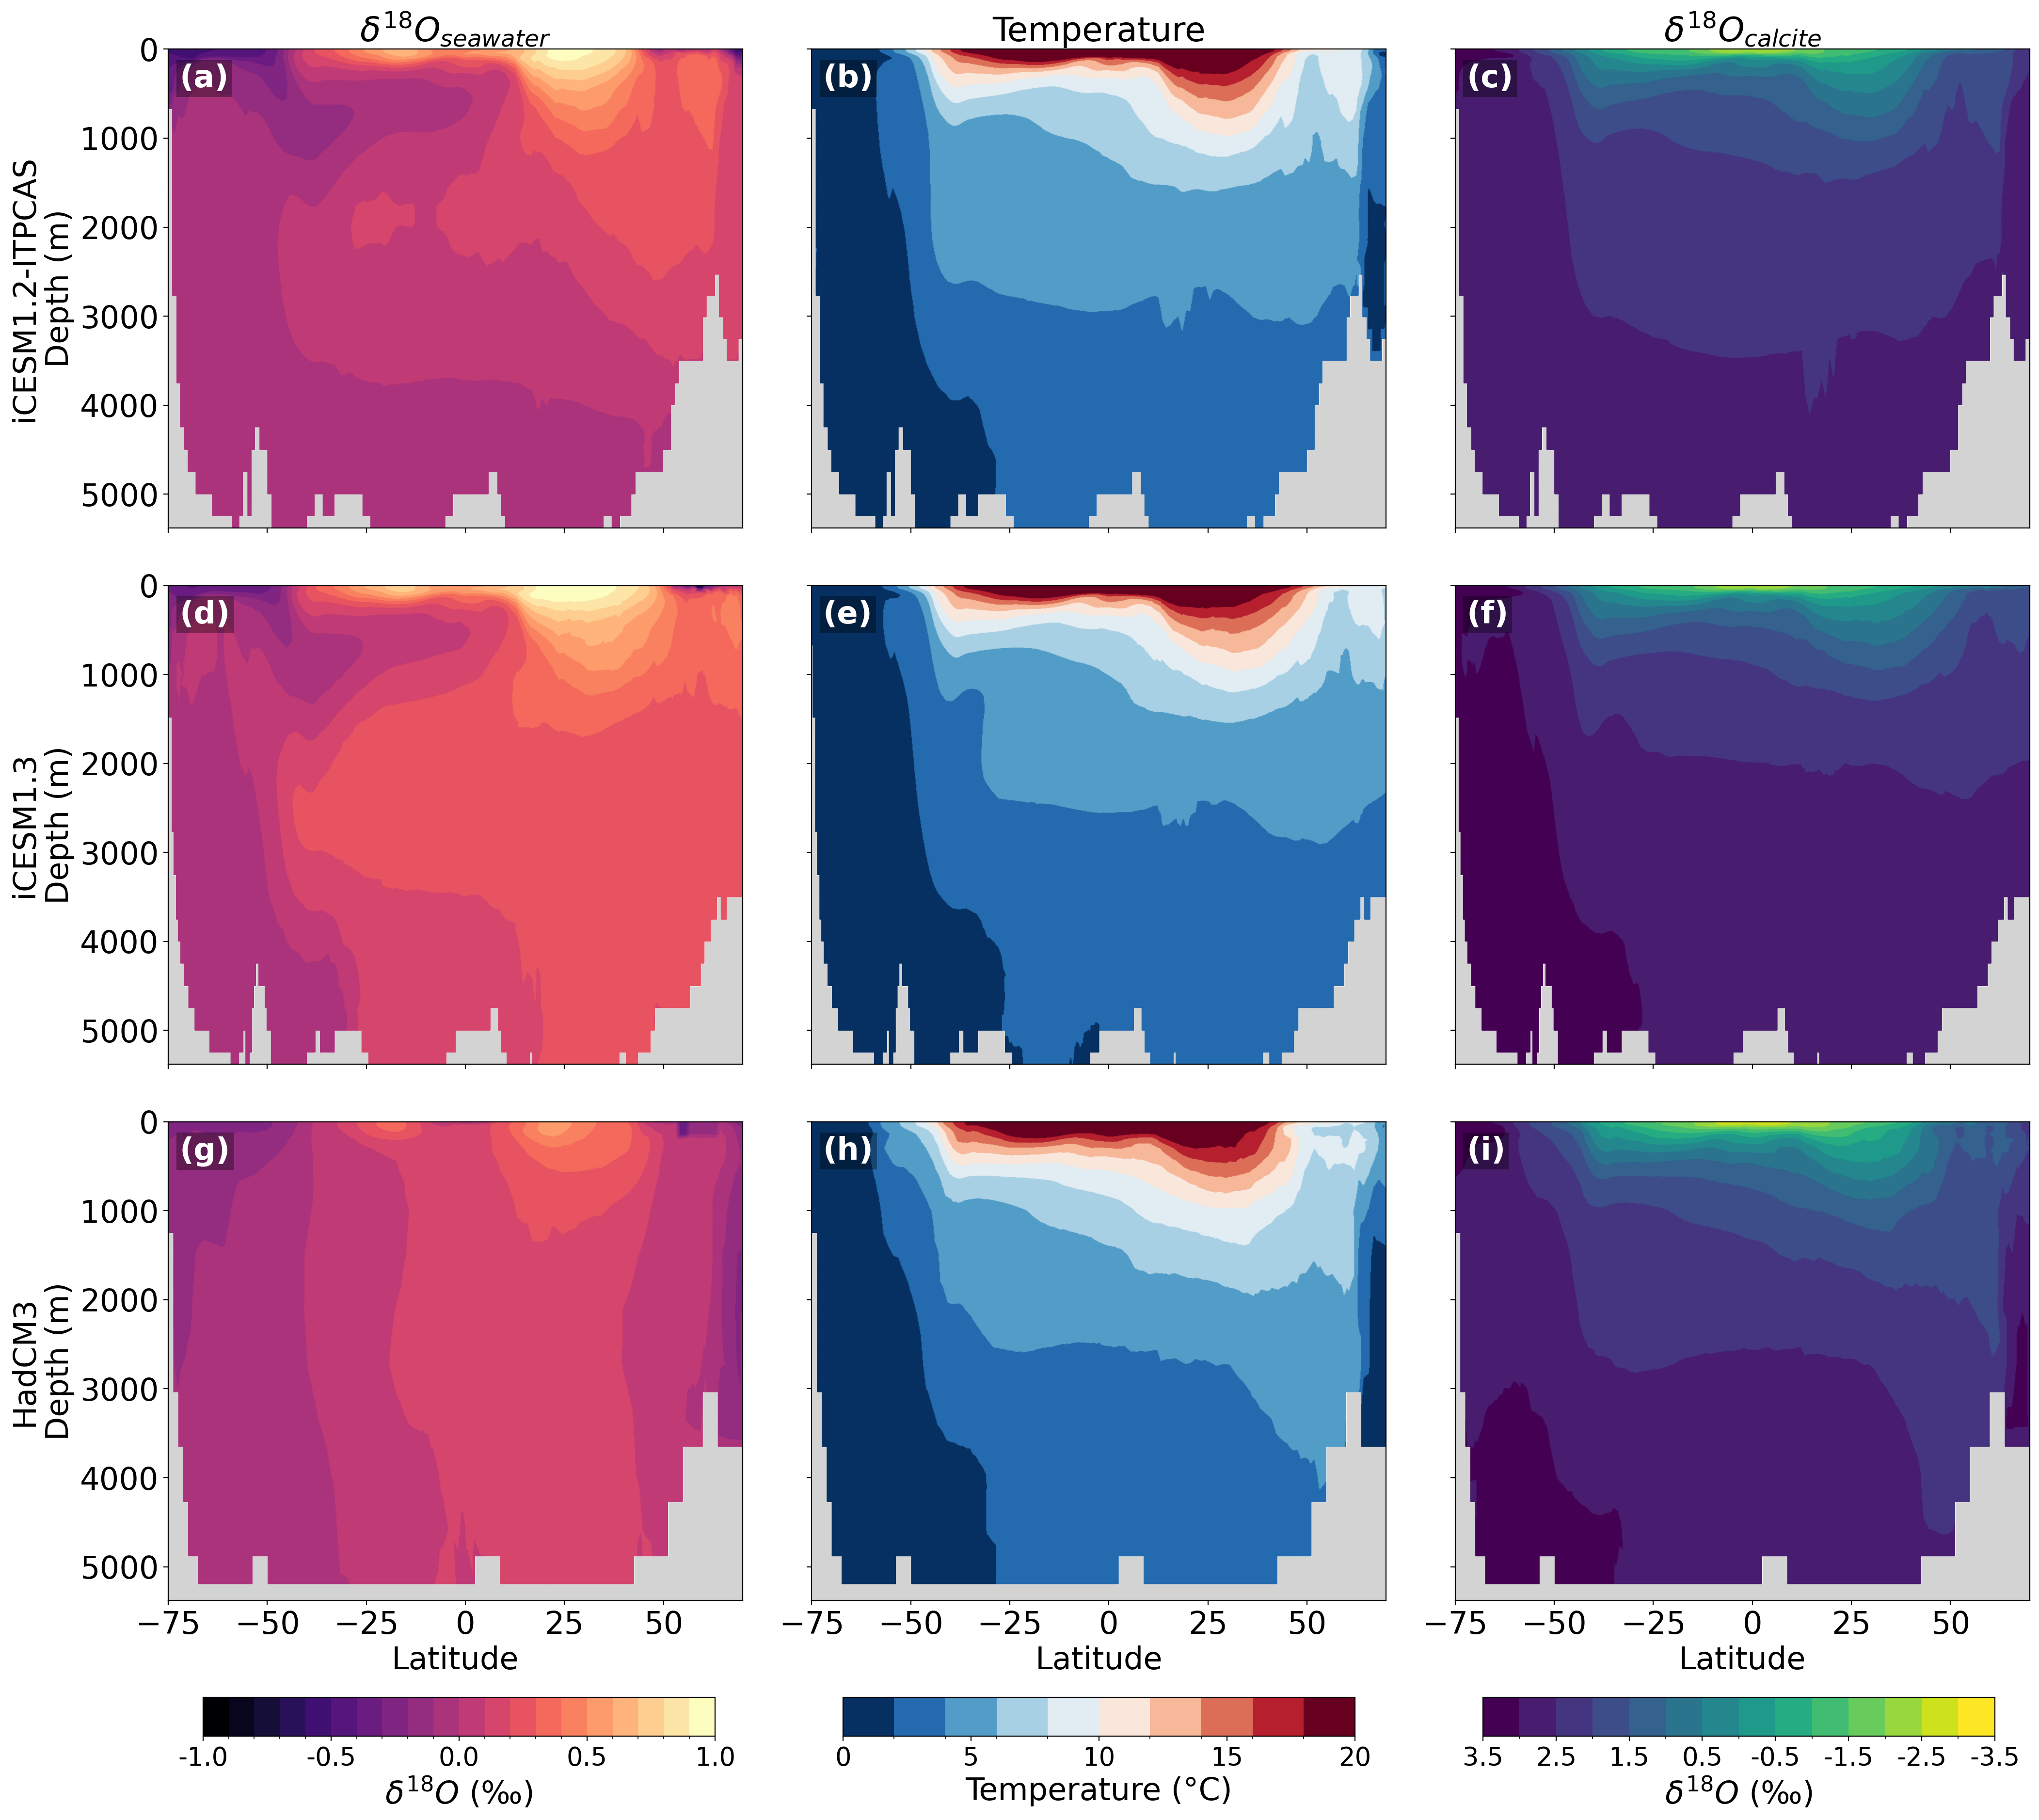

In [3]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from matplotlib.gridspec import GridSpec

# Define font sizes (match cell 186)
TITLE_SIZE = 25
LABEL_SIZE = 23
TICK_SIZE = 23
CBAR_LABEL_SIZE = 23
CBAR_TICK_SIZE = 19

# Create figure
fig = plt.figure(figsize=(24, 20), dpi=200)

# Create a single GridSpec for the 3x3 plot grid
gs = GridSpec(
    3, 3, figure=fig,
    top=0.94, bottom=0.14, left=0.10, right=0.90,
    hspace=0.12, wspace=0.12
)

# Set global font sizes
plt.rcParams['font.size'] = LABEL_SIZE
plt.rcParams['axes.titlesize'] = TITLE_SIZE
plt.rcParams['axes.labelsize'] = LABEL_SIZE
plt.rcParams['xtick.labelsize'] = TICK_SIZE
plt.rcParams['ytick.labelsize'] = TICK_SIZE

# Column titles (top row only)
column_titles = [r'$\delta^{18}O_{seawater}$', 'Temperature', r'$\delta^{18}O_{calcite}$']
row_titles = ['iCESM1.2-ITPCAS', 'iCESM1.3', 'HadCM3']

# Colormaps and norms (match cell 186)
col1_color_bins = np.arange(-1, 1.01, 0.1)
col1_cmap = mcolors.ListedColormap(plt.cm.magma(np.linspace(0, 1, len(col1_color_bins) - 1)))
col1_norm = mcolors.BoundaryNorm(boundaries=col1_color_bins, ncolors=len(col1_color_bins) - 1)

col2_color_bins = np.arange(0, 21, 2)
col2_cmap = mcolors.ListedColormap(plt.cm.RdBu_r(np.linspace(0, 1, len(col2_color_bins) - 1)))
col2_norm = mcolors.BoundaryNorm(boundaries=col2_color_bins, ncolors=len(col2_color_bins) - 1)

col3_color_bins = np.arange(-3.5, 3.6, 0.5)
col3_cmap = mcolors.ListedColormap(plt.cm.viridis_r(np.linspace(0, 1, len(col3_color_bins) - 1)))
col3_norm = mcolors.BoundaryNorm(boundaries=col3_color_bins, ncolors=len(col3_color_bins) - 1)

# -----------------------
# ROW 1: iCESM1.2-ITPCAS
# -----------------------
ax1 = fig.add_subplot(gs[0, 0])
r1_c1, lat_r1c1, dep_r1c1 = latdepthplot(preind_lat, preind_lon, preind_depth, preind_d18O, mesh=True, normalise=False)
shade_below_bathymetry(ax1, lat_r1c1, dep_r1c1, r1_c1)
pc1 = ax1.pcolormesh(lat_r1c1, dep_r1c1, r1_c1, cmap=col1_cmap, norm=col1_norm, shading='gouraud')
ax1.set_ylim(0, 5380); ax1.set_xlim([-75, 70]); ax1.invert_yaxis()
ax1.set_title(column_titles[0], fontsize=TITLE_SIZE)
ax1.set_ylabel(f'{row_titles[0]}\nDepth (m)', fontsize=LABEL_SIZE)
ax1.tick_params(axis='both', which='major', labelsize=TICK_SIZE)

ax2 = fig.add_subplot(gs[0, 1])
r1_c2, lat_r1c2, dep_r1c2 = latdepthplot(preind_temp_lat, preind_temp_lon, preind_depth, preind_temp, mesh=False, normalise=False)
shade_below_bathymetry(ax2, lat_r1c2, dep_r1c2, r1_c2)
pc2 = ax2.pcolormesh(lat_r1c2, dep_r1c2, r1_c2, cmap=col2_cmap, norm=col2_norm, shading='gouraud')
ax2.set_ylim(0, 5380); ax2.set_xlim([-75, 70]); ax2.invert_yaxis()
ax2.set_title(column_titles[1], fontsize=TITLE_SIZE)
ax2.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax2.tick_params(axis='y', labelleft=False)

ax3 = fig.add_subplot(gs[0, 2])
r1_c3, lat_r1c3, dep_r1c3 = temperatureadjustedplot(
    preind_lat, preind_lon, preind_depth, preind_d18O, preind_temp,
    mesh=True, samegrid=False, templat=preind_temp_lat, templon=preind_temp_lon, tempmesh=False, normalise=False
)
shade_below_bathymetry(ax3, lat_r1c3, dep_r1c3, r1_c3)
pc3 = ax3.pcolormesh(lat_r1c3, dep_r1c3, r1_c3, cmap=col3_cmap, norm=col3_norm, shading='gouraud')
ax3.set_ylim(0, 5380); ax3.set_xlim([-75, 70]); ax3.invert_yaxis()
ax3.set_title(column_titles[2], fontsize=TITLE_SIZE)
ax3.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax3.tick_params(axis='y', labelleft=False)

# ----------
# ROW 2: iCESM1.3
# ----------
ax4 = fig.add_subplot(gs[1, 0])
r2_c1, lat_r2c1, dep_r2c1 = latdepthplot(icesm13_preind_lat, icesm13_preind_lon, icesm13_preind_depth, icesm13_preind_d18O, mesh=True, normalise=False)
shade_below_bathymetry(ax4, lat_r2c1, dep_r2c1, r2_c1)
pc4 = ax4.pcolormesh(lat_r2c1, dep_r2c1, r2_c1, cmap=col1_cmap, norm=col1_norm, shading='gouraud')
ax4.set_ylim(0, 5380); ax4.set_xlim([-75, 70]); ax4.invert_yaxis()
ax4.set_ylabel(f'{row_titles[1]}\nDepth (m)', fontsize=LABEL_SIZE)
ax4.tick_params(axis='both', which='major', labelsize=TICK_SIZE)

ax5 = fig.add_subplot(gs[1, 1])
r2_c2, lat_r2c2, dep_r2c2 = latdepthplot(icesm13_preind_lat, icesm13_preind_lon, icesm13_preind_depth, icesm13_preind_temp, mesh=True, normalise=False)
shade_below_bathymetry(ax5, lat_r2c2, dep_r2c2, r2_c2)
pc5 = ax5.pcolormesh(lat_r2c2, dep_r2c2, r2_c2, cmap=col2_cmap, norm=col2_norm, shading='gouraud')
ax5.set_ylim(0, 5380); ax5.set_xlim([-75, 70]); ax5.invert_yaxis()
ax5.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax5.tick_params(axis='y', labelleft=False)

ax6 = fig.add_subplot(gs[1, 2])
r2_c3, lat_r2c3, dep_r2c3 = temperatureadjustedplot(
    icesm13_preind_lat, icesm13_preind_lon, icesm13_preind_depth, icesm13_preind_d18O, icesm13_preind_temp,
    mesh=True, normalise=False
)
shade_below_bathymetry(ax6, lat_r2c3, dep_r2c3, r2_c3)
pc6 = ax6.pcolormesh(lat_r2c3, dep_r2c3, r2_c3, cmap=col3_cmap, norm=col3_norm, shading='gouraud')
ax6.set_ylim(0, 5380); ax6.set_xlim([-75, 70]); ax6.invert_yaxis()
ax6.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax6.tick_params(axis='y', labelleft=False)

# ----------
# ROW 3: HadCM3
# ----------
ax7 = fig.add_subplot(gs[2, 0])
r3_c1, lat_r3c1, dep_r3c1 = latdepthplot(hadcm3_preind_lat, hadcm3_preind_lon, hadcm3_preind_depth, hadcm3_preind_d18O, normalise=False)
shade_below_bathymetry(ax7, lat_r3c1, dep_r3c1, r3_c1)
pc7 = ax7.pcolormesh(lat_r3c1, dep_r3c1, r3_c1, cmap=col1_cmap, norm=col1_norm, shading='gouraud')
ax7.set_ylim(0, 5380); ax7.set_xlim([-75, 70]); ax7.invert_yaxis()
ax7.set_xlabel('Latitude', fontsize=LABEL_SIZE)
ax7.set_ylabel(f'{row_titles[2]}\nDepth (m)', fontsize=LABEL_SIZE)
ax7.tick_params(axis='both', which='major', labelsize=TICK_SIZE)

ax8 = fig.add_subplot(gs[2, 1])
r3_c2, lat_r3c2, dep_r3c2 = latdepthplot(hadcm3_preind_lat, hadcm3_preind_lon, hadcm3_preind_depth, hadcm3_preind_temp, normalise=False)
shade_below_bathymetry(ax8, lat_r3c2, dep_r3c2, r3_c2)
pc8 = ax8.pcolormesh(lat_r3c2, dep_r3c2, r3_c2, cmap=col2_cmap, norm=col2_norm, shading='gouraud')
ax8.set_ylim(0, 5380); ax8.set_xlim([-75, 70]); ax8.invert_yaxis()
ax8.set_xlabel('Latitude', fontsize=LABEL_SIZE)
ax8.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax8.tick_params(axis='y', labelleft=False)

ax9 = fig.add_subplot(gs[2, 2])
r3_c3, lat_r3c3, dep_r3c3 = temperatureadjustedplot(
    hadcm3_preind_lat, hadcm3_preind_lon, hadcm3_preind_depth, hadcm3_preind_d18O, hadcm3_preind_temp, normalise=False
)
shade_below_bathymetry(ax9, lat_r3c3, dep_r3c3, r3_c3)
pc9 = ax9.pcolormesh(lat_r3c3, dep_r3c3, r3_c3, cmap=col3_cmap, norm=col3_norm, shading='gouraud')
ax9.set_ylim(0, 5380); ax9.set_xlim([-75, 70]); ax9.invert_yaxis()
ax9.set_xlabel('Latitude', fontsize=LABEL_SIZE)
ax9.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
ax9.tick_params(axis='y', labelleft=False)

# Hide x tick labels for top two rows
for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
    ax.set_xticklabels([])

# Colorbars (same positions/style as cell 186)
cbar_ax1 = fig.add_axes([0.115, 0.07, 0.22, 0.02])
cbar1 = plt.colorbar(pc1, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'$\delta^{18}O$ (‰)', fontsize=CBAR_LABEL_SIZE)
cbar1.set_ticks([-1.0, -0.5, 0.0, 0.5, 1.0])
cbar1.set_ticklabels(['-1.0', '-0.5', '0.0', '0.5', '1.0'])
cbar1.ax.tick_params(labelsize=CBAR_TICK_SIZE)

cbar_ax2 = fig.add_axes([0.39, 0.07, 0.22, 0.02])
cbar2 = plt.colorbar(pc2, cax=cbar_ax2, orientation='horizontal')
cbar2.set_label('Temperature (°C)', fontsize=CBAR_LABEL_SIZE)
cbar2.set_ticks([0, 5, 10, 15, 20])
cbar2.set_ticklabels(['0', '5', '10', '15', '20'])
cbar2.ax.tick_params(labelsize=CBAR_TICK_SIZE)

cbar_ax3 = fig.add_axes([0.665, 0.07, 0.22, 0.02])
cbar3 = plt.colorbar(pc3, cax=cbar_ax3, orientation='horizontal')
cbar3.set_ticks(col3_color_bins[::2])
cbar3.set_ticklabels([f"{t:g}" for t in col3_color_bins[::2]])
cbar3.set_label(r'$\delta^{18}O$ (‰)', fontsize=CBAR_LABEL_SIZE)
cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)
cbar3.ax.invert_xaxis()
panel_axes = [ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9]
panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)", "(g)", "(h)", "(i)"]

for ax, lab in zip(panel_axes, panel_labels):
    ax.text(
        0.02, 0.97, lab,
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=23, fontweight='bold', color='white',
        bbox=dict(facecolor='black', edgecolor='none', alpha=0.35, pad=2.5)
    )


fig.savefig(FIG_DIR / "d18O_calcite_PI_3x3.png", dpi=300, bbox_inches="tight")
plt.show()
